<a href="https://colab.research.google.com/github/rifaa05/Project-Akhir_ML_5C_Kelompok-2/blob/main/01_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Eksplorasi Data (EDA)

**Proyek Akhir Pembelajaran Mesin (INF62325) — Kelas 5C**  
**Paket:** 5C-3 Heart Failure Prediction  
**Metode kelompok:** Klasifikasi (k-NN dibandingkan Naive Bayes)  
**Anggota:** Adel Zamalya (2488010059), Adam Fadli (2488010028), Rifa’ah Fatihatu Sa’adah (2488010008)

Notebook ini mengikuti delapan langkah dalam *Panduan Eksplorasi Data Mahasiswa 5C*: memahami sumber, memuat data, menetapkan unit analisis, memeriksa mutu, memahami target, memeriksa hubungan/kebocoran, membuat visualisasi yang ditafsirkan, dan mencatat keputusan awal.

**Catatan:** dataset kesehatan ini hanya digunakan untuk latihan pembelajaran mesin. Hasil model bukan diagnosis atau saran klinis.

## 0. Informasi sumber dan pemahaman data

Sumber dataset: [Heart Failure Prediction — Kaggle (Fedesoriano)](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).

Satu baris merepresentasikan **satu pasien**. Dataset merupakan gabungan lima dataset jantung yang lebih kecil. Kolom berisi demografi, gejala, pengukuran klinis, hasil pemeriksaan, dan label `HeartDisease`.

Keterbatasan konteks: berkas gabungan tidak menyediakan identitas sumber asal tiap baris dan tidak menjelaskan secara lengkap waktu pengumpulan untuk setiap sumber. Karena itu, variasi antar-sumber dapat memengaruhi distribusi fitur.

In [ ]:
# ==========================================
# DOWNLOAD DATASET HEART FAILURE PREDICTION
# ==========================================

!pip install -q kagglehub

import kagglehub
import pandas as pd
import shutil
from pathlib import Path

# Download dataset dari Kaggle
dataset_path = kagglehub.dataset_download(
    "fedesoriano/heart-failure-prediction"
)

# Cari file heart.csv
dataset_file = list(Path(dataset_path).rglob("heart.csv"))[0]

# Buat folder data
Path("data").mkdir(exist_ok=True)

# Salin dataset ke folder proyek
shutil.copy(dataset_file, "data/heart.csv")

# Baca dataset
df = pd.read_csv("data/heart.csv")

print("Dataset berhasil diunduh!")
print("Lokasi:", dataset_file)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Dataset berhasil diunduh!
Lokasi: /kaggle/input/heart-failure-prediction/heart.csv
Jumlah baris: 918
Jumlah kolom: 12


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
nama_file = next(iter(uploaded))


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (8, 5)

DATA_PATH = Path("heart (2).csv")

df = pd.read_csv(DATA_PATH, sep=",", encoding="utf-8")

print("Sumber file:", DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head())

Sumber file: heart (2).csv
Ukuran dataset: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 1. Potret struktur dan unit analisis

Unit analisis: **satu baris = satu pasien**. Tidak ada kolom ID pasien pada berkas ini, sehingga satu baris tidak dapat ditautkan ke identitas individu tertentu.

In [ ]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Nama kolom:", df.columns.tolist())
print("\nInformasi tipe data:")
df.info()
print("\nStatistik deskriptif numerik:")
display(df.describe().T)
print("\nStatistik deskriptif kategorikal:")
display(df.describe(include="object").T)
print("\nTipe data:")
display(df.dtypes.to_frame("dtype"))

Jumlah baris: 918
Jumlah kolom: 12
Nama kolom: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
mem

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0



Statistik deskriptif kategorikal:


,count,unique,top,freq
Sex,918,2,M,725
ChestPainType,918,4,ASY,496
RestingECG,918,3,Normal,552
ExerciseAngina,918,2,N,547
ST_Slope,918,3,Flat,460



Tipe data:


,dtype
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64


### Kamus data

Arti dan satuan diringkas berdasarkan dokumentasi dataset Heart Failure Prediction. `FastingBS` dan `HeartDisease` berupa kode biner, bukan besaran kontinu.

In [ ]:
kamus_data = pd.DataFrame([
    ["Age", "Usia pasien", "tahun", "numerik bulat", "fitur", "Periksa rentang dan pencilan"],
    ["Sex", "Jenis kelamin (M/F)", "-", "kategori", "fitur", "Label kategori"],
    ["ChestPainType", "Jenis nyeri dada (TA, ATA, NAP, ASY)", "-", "kategori", "fitur", "Kode kategori"],
    ["RestingBP", "Tekanan darah saat istirahat", "mmHg", "numerik bulat", "fitur", "Nilai 0 dianggap data hilang tersamar"],
    ["Cholesterol", "Kolesterol serum", "mg/dL", "numerik bulat", "fitur", "Nilai 0 dianggap data hilang tersamar"],
    ["FastingBS", "Gula darah puasa > 120 mg/dL (1=ya, 0=tidak)", "biner", "kategori biner", "fitur", "Nilai 0 dan 1 adalah kode sah"],
    ["RestingECG", "Hasil elektrokardiogram saat istirahat", "-", "kategori", "fitur", "Label kategori"],
    ["MaxHR", "Denyut jantung maksimum yang dicapai", "denyut/menit", "numerik bulat", "fitur", "Periksa sebaran dan pencilan"],
    ["ExerciseAngina", "Angina akibat olahraga (Y/N)", "-", "kategori biner", "fitur", "Label kategori"],
    ["Oldpeak", "Depresi ST akibat olahraga dibanding istirahat", "mm", "numerik kontinu", "fitur", "Periksa sebaran dan pencilan"],
    ["ST_Slope", "Kemiringan segmen ST saat puncak latihan (Up/Flat/Down)", "-", "kategori", "fitur", "Label kategori"],
    ["HeartDisease", "Penanda penyakit jantung (1=ada, 0=tidak)", "biner", "target biner", "target", "Target klasifikasi"]
], columns=["Nama kolom", "Arti", "Satuan", "Tipe ditetapkan", "Peran", "Catatan mutu"])
display(kamus_data)
kamus_data.to_csv("../kamus_data.csv", index=False)

,Nama kolom,Arti,Satuan,Tipe ditetapkan,Peran,Catatan mutu
0,Age,Usia pasien,tahun,numerik bulat,fitur,Periksa rentang dan pencilan
1,Sex,Jenis kelamin (M/F),-,kategori,fitur,Label kategori
2,ChestPainType,"Jenis nyeri dada (TA, ATA, NAP, ASY)",-,kategori,fitur,Kode kategori
3,RestingBP,Tekanan darah saat istirahat,mmHg,numerik bulat,fitur,Nilai 0 dianggap data hilang tersamar
4,Cholesterol,Kolesterol serum,mg/dL,numerik bulat,fitur,Nilai 0 dianggap data hilang tersamar
5,FastingBS,"Gula darah puasa > 120 mg/dL (1=ya, 0=tidak)",biner,kategori biner,fitur,Nilai 0 dan 1 adalah kode sah
6,RestingECG,Hasil elektrokardiogram saat istirahat,-,kategori,fitur,Label kategori
7,MaxHR,Denyut jantung maksimum yang dicapai,denyut/menit,numerik bulat,fitur,Periksa sebaran dan pencilan
8,ExerciseAngina,Angina akibat olahraga (Y/N),-,kategori biner,fitur,Label kategori
9,Oldpeak,Depresi ST akibat olahraga dibanding istirahat,mm,numerik kontinu,fitur,Periksa sebaran dan pencilan


## 2. Pemeriksaan kebersihan data

Pemeriksaan mengikuti panduan: nilai hilang eksplisit, nilai hilang tersamar, duplikat, kolom konstan/identifier, nilai mustahil/pencilan, dan konsistensi kategori.

In [ ]:
# 2a. Missing value eksplisit
missing = pd.DataFrame({
    "jumlah": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(2)
})
display(missing)
print("Total missing eksplisit:", int(df.isna().sum().sum()))

# 2b. Missing value tersamar: nol pada tekanan darah dan kolesterol
for col in ["RestingBP", "Cholesterol"]:
    print(f"{col}=0: {(df[col] == 0).sum()} baris ({(df[col] == 0).mean()*100:.2f}%)")

# 2c. Duplikat
print("Duplikat seluruh baris:", int(df.duplicated().sum()))

# 2d. Kolom konstan dan kandidat identifier
nunique = df.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()
near_unique_cols = nunique[nunique > 0.9 * len(df)].index.tolist()
print("Kolom konstan:", constant_cols)
print("Kandidat identifier (>90% nilai unik):", near_unique_cols)

# 2e. Rentang dasar dan pencilan IQR (indikator pemeriksaan, bukan instruksi otomatis menghapus)
num_cols = df.select_dtypes(include=np.number).columns.tolist()
ringkasan = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = int(((s < bawah) | (s > atas)).sum())
    ringkasan.append([col, s.min(), s.max(), bawah, atas, count])
outlier_iqr = pd.DataFrame(ringkasan, columns=["Kolom", "Minimum", "Maksimum", "Batas bawah IQR", "Batas atas IQR", "Jumlah di luar pagar"])
display(outlier_iqr)

# Pemeriksaan nilai negatif untuk kolom yang secara domain tidak semestinya negatif
for col in ["Age", "RestingBP", "Cholesterol", "MaxHR"]:
    print(f"{col} < 0:", int((df[col] < 0).sum()))

# 2f. Konsistensi kategori
cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    print("\n", col, sorted(df[col].dropna().astype(str).unique().tolist()))

,jumlah,persen
Age,0,0.0
Sex,0,0.0
ChestPainType,0,0.0
RestingBP,0,0.0
Cholesterol,0,0.0
FastingBS,0,0.0
RestingECG,0,0.0
MaxHR,0,0.0
ExerciseAngina,0,0.0
Oldpeak,0,0.0


Total missing eksplisit: 0
RestingBP=0: 1 baris (0.11%)
Cholesterol=0: 172 baris (18.74%)
Duplikat seluruh baris: 0
Kolom konstan: []
Kandidat identifier (>90% nilai unik): []


,Kolom,Minimum,Maksimum,Batas bawah IQR,Batas atas IQR,Jumlah di luar pagar
0,Age,28.0,77.0,27.500,79.500,0
1,RestingBP,0.0,200.0,90.000,170.000,28
2,Cholesterol,0.0,603.0,32.625,407.625,183
3,FastingBS,0.0,1.0,0.000,0.000,214
4,MaxHR,60.0,202.0,66.000,210.000,2
5,Oldpeak,-2.6,6.2,-2.250,3.750,16
6,HeartDisease,0.0,1.0,-1.500,2.500,0


Age < 0: 0
RestingBP < 0: 0
Cholesterol < 0: 0
MaxHR < 0: 0

 Sex ['F', 'M']

 ChestPainType ['ASY', 'ATA', 'NAP', 'TA']

 RestingECG ['LVH', 'Normal', 'ST']

 ExerciseAngina ['N', 'Y']

 ST_Slope ['Down', 'Flat', 'Up']


### Interpretasi pemeriksaan mutu

- `isna()` menunjukkan tidak ada missing value eksplisit pada data mentah. Namun pemeriksaan khusus menemukan **172 nilai `Cholesterol=0`** dan **1 nilai `RestingBP=0`**. Berdasarkan catatan khusus paket 5C-3, nol pada kedua pengukuran ini diperlakukan sebagai missing tersamar, bukan nilai klinis yang sah.
- Tidak ditemukan baris duplikat identik. Dataset tidak memiliki kolom konstan maupun identifier yang hampir unik.
- Jumlah pencilan IQR hanya menjadi penanda untuk ditinjau. Pencilan statistik tidak otomatis salah; nilai ekstrem yang masih mungkin secara nyata tidak dihapus tanpa alasan domain.
- Kategori ditinjau melalui daftar nilai unik. Kode seperti `TA`, `ATA`, `NAP`, dan `ASY` dipertahankan sebagai kategori, bukan angka berurutan.

## 3. Memahami target klasifikasi

Target kelompok adalah `HeartDisease`: 1 berarti label penyakit jantung ada dan 0 berarti tidak ada. Hitung jumlah, persentase, dan garis dasar kelas mayoritas sebelum pemodelan.

In [ ]:
target = "HeartDisease"
jumlah_kelas = df[target].value_counts().sort_index()
persen_kelas = (df[target].value_counts(normalize=True).sort_index() * 100).round(2)
ringkasan_target = pd.DataFrame({"Jumlah": jumlah_kelas, "Persentase (%)": persen_kelas})
display(ringkasan_target)
majority_class = int(df[target].value_counts().idxmax())
baseline = df[target].value_counts(normalize=True).max()
print(f"Kelas mayoritas: {majority_class}")
print(f"Garis dasar kelas mayoritas: {baseline:.4%}")

,Jumlah,Persentase (%)
HeartDisease,,
0,410,44.66
1,508,55.34


Kelas mayoritas: 1
Garis dasar kelas mayoritas: 55.3377%


**Interpretasi target:** kelas target relatif berimbang, tetapi kelas 1 sedikit lebih banyak. Garis dasar yang harus dilampaui model adalah akurasi jika seluruh pasien selalu diprediksi sebagai kelas mayoritas. Garis dasar ini menjadi pembanding, bukan bukti bahwa model sudah baik.

## 4. Hubungan fitur dan pemeriksaan kebocoran

Periksa korelasi numerik terhadap target, korelasi antarfitur, serta kemungkinan fitur yang secara definisi merupakan target. Korelasi tinggi adalah sinyal untuk ditinjau, bukan satu-satunya bukti kebocoran.

In [ ]:
corr = df.select_dtypes(include=np.number).corr(numeric_only=True)
if target in corr.columns:
    corr_target = corr[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)
    display(corr_target.to_frame("Korelasi dengan HeartDisease"))
    print("Kandidat korelasi absolut > 0.95:", corr_target[ corr_target.abs() > 0.95 ].index.tolist())

# Cari pasangan fitur numerik yang sangat berkorelasi
feature_corr = corr.drop(index=target, columns=target, errors="ignore").abs()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Pasangan fitur dengan |korelasi| > 0.80:")
display(pairs[pairs > 0.80].to_frame("Korelasi absolut"))

# Pastikan tidak ada fitur lain yang identik langsung dengan target
for col in df.columns.drop(target):
    if df[col].nunique(dropna=False) == 2:
        print(f"{col}: sama persis dengan target?", bool((df[col].astype(str) == df[target].astype(str)).all()))

# Tabulasi fitur kategori terhadap target
for col in cat_cols:
    print("\nTabel silang:", col)
    display(pd.crosstab(df[col], df[target], normalize="index").round(3))

,Korelasi dengan HeartDisease
Oldpeak,0.403951
MaxHR,-0.400421
Age,0.282039
FastingBS,0.267291
Cholesterol,-0.232741
RestingBP,0.107589


Kandidat korelasi absolut > 0.95: []
Pasangan fitur dengan |korelasi| > 0.80:


,,Korelasi absolut


Sex: sama persis dengan target? False
FastingBS: sama persis dengan target? False
ExerciseAngina: sama persis dengan target? False

Tabel silang: Sex


HeartDisease,0,1
Sex,,
F,0.741,0.259
M,0.368,0.632



Tabel silang: ChestPainType


... (3 outputs left out)


Tabel silang: ExerciseAngina


HeartDisease,0,1
ExerciseAngina,,
N,0.649,0.351
Y,0.148,0.852



Tabel silang: ST_Slope


HeartDisease,0,1
ST_Slope,,
Down,0.222,0.778
Flat,0.172,0.828
Up,0.803,0.197


### Interpretasi hubungan dan risiko kebocoran

Pada dataset ini `HeartDisease` merupakan label yang akan diprediksi. Kolom fitur yang tersedia adalah atribut pasien dan hasil pemeriksaan. Pemeriksaan korelasi numerik dan tabulasi kategori digunakan untuk mencari hubungan yang mencurigakan. Tidak boleh menyimpulkan “tidak ada kebocoran” hanya dari korelasi; tetap perlu menilai apakah fitur tersedia pada saat prediksi dan apakah fitur merupakan turunan langsung target.

Dataset gabungan lima sumber juga berpotensi memiliki perbedaan distribusi antar sumber asal. Informasi sumber asal tidak tersedia sebagai kolom, sehingga efek tersebut tidak dapat diuji secara langsung.

## 5. Visualisasi yang menjawab pertanyaan

Setiap grafik di bawah disertai interpretasi otomatis berdasarkan pola yang terlihat atau angka ringkasan. Grafik dibuat secukupnya agar setiap visual memiliki tujuan.

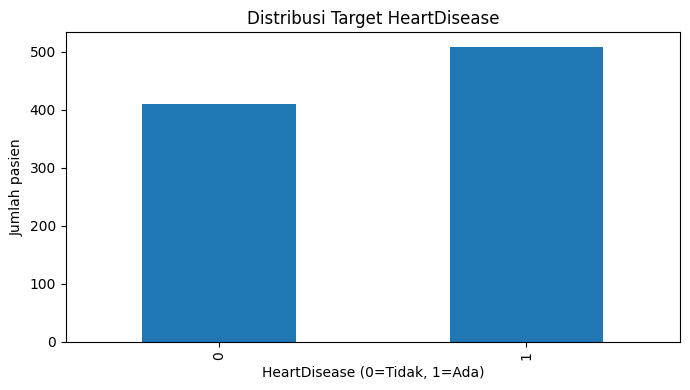

Interpretasi: kelas mayoritas 1 mencakup 55.34% data; distribusi relatif berimbang, sehingga akurasi perlu dibaca bersama precision, recall, F1, dan confusion matrix.


In [ ]:
# Grafik 1 — Apakah target seimbang?
counts = df[target].value_counts().sort_index()
ax = counts.plot(kind="bar", figsize=(7, 4))
ax.set(title="Distribusi Target HeartDisease", xlabel="HeartDisease (0=Tidak, 1=Ada)", ylabel="Jumlah pasien", xticklabels=counts.index)
plt.tight_layout()
plt.show()
print(f"Interpretasi: kelas mayoritas {majority_class} mencakup {baseline:.2%} data; distribusi relatif berimbang, sehingga akurasi perlu dibaca bersama precision, recall, F1, dan confusion matrix.")

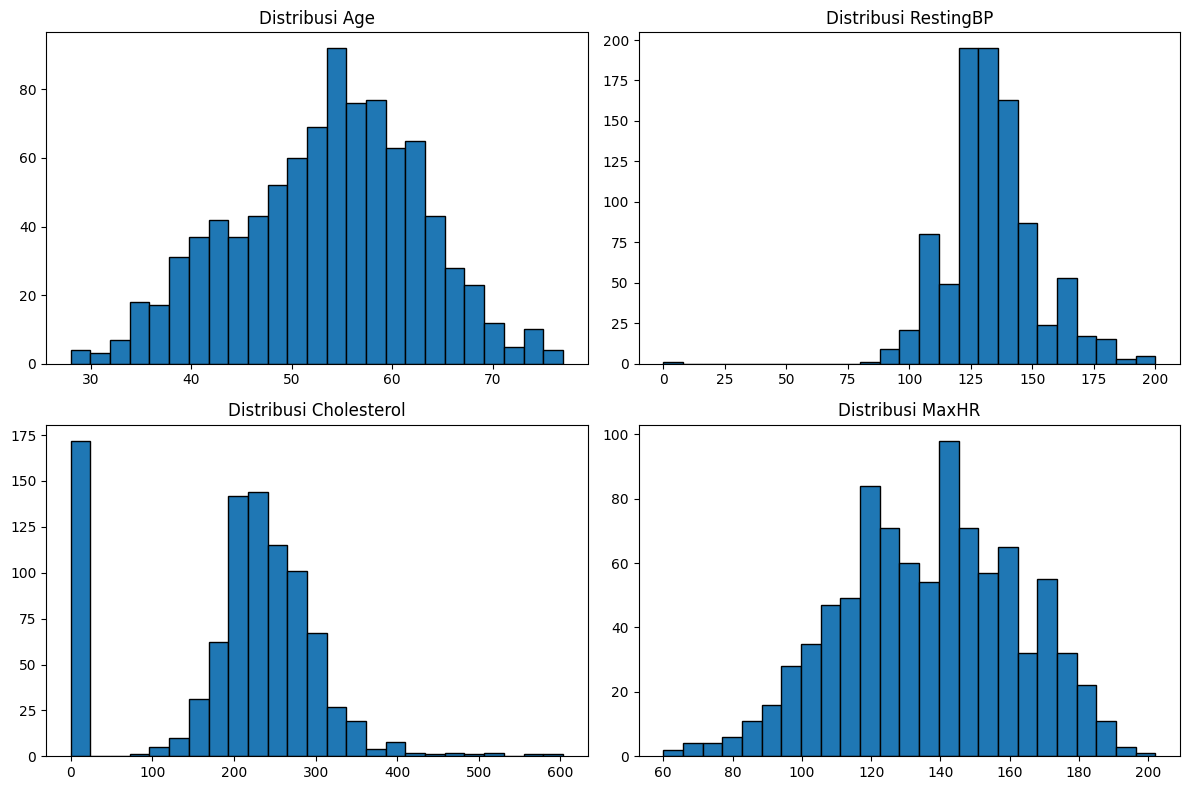

Interpretasi: histogram digunakan untuk melihat kemencengan, penumpukan nilai, dan nilai nol yang tidak wajar. Cholesterol memiliki penumpukan nilai nol yang perlu ditandai sebagai missing tersamar.


In [ ]:
# Grafik 2 — Bentuk sebaran fitur numerik utama
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Age", "RestingBP", "Cholesterol", "MaxHR"]):
    ax.hist(df[col].dropna(), bins=25, edgecolor="black")
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.show()
print("Interpretasi: histogram digunakan untuk melihat kemencengan, penumpukan nilai, dan nilai nol yang tidak wajar. Cholesterol memiliki penumpukan nilai nol yang perlu ditandai sebagai missing tersamar.")

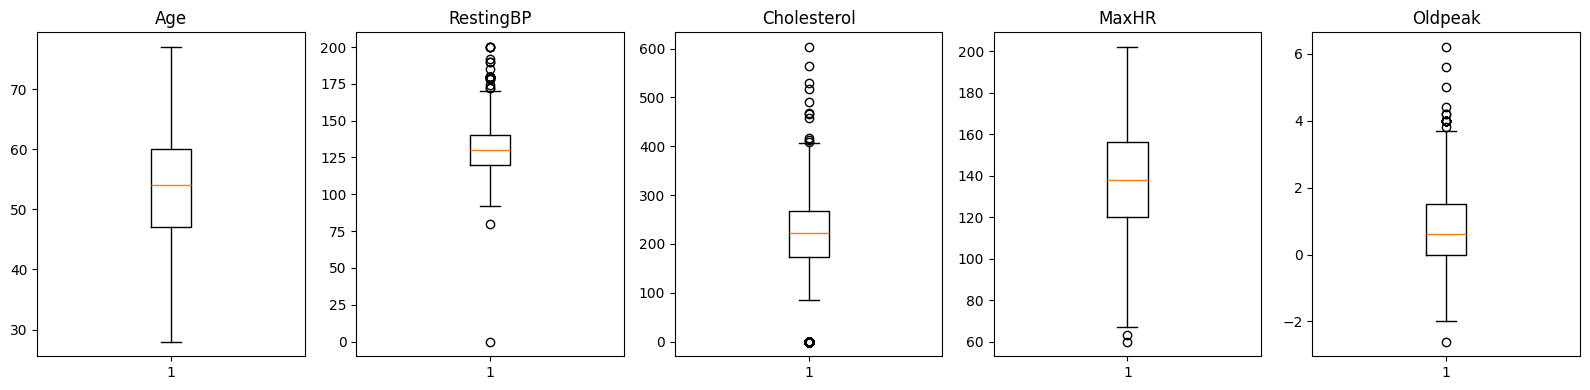

Interpretasi: titik di luar whisker adalah kandidat pencilan IQR, bukan otomatis kesalahan. Nilai diperiksa berdasarkan makna variabel sebelum keputusan pembersihan.


In [ ]:
# Grafik 3 — Pencilan statistik pada fitur numerik
cols_box = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, len(cols_box), figsize=(16, 4))
for ax, col in zip(axes, cols_box):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()
print("Interpretasi: titik di luar whisker adalah kandidat pencilan IQR, bukan otomatis kesalahan. Nilai diperiksa berdasarkan makna variabel sebelum keputusan pembersihan.")

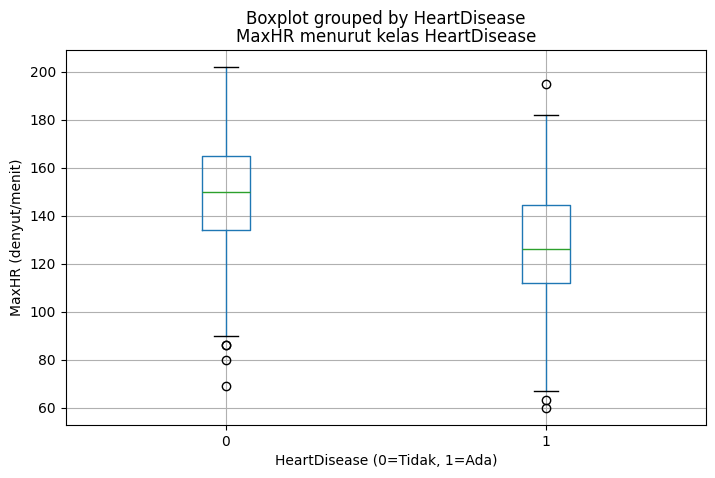

Interpretasi: pergeseran median atau rentang MaxHR antar kelas menunjukkan perbedaan distribusi, tetapi tumpang tindih antarkelompok berarti fitur ini tidak memisahkan kelas secara sempurna.


In [ ]:
# Grafik 4 — Apakah sebaran Age dan MaxHR berbeda menurut kelas?
plt.figure(figsize=(8, 5))
df.boxplot(column="MaxHR", by=target, ax=plt.gca())
plt.title("MaxHR menurut kelas HeartDisease")
plt.xlabel("HeartDisease (0=Tidak, 1=Ada)")
plt.ylabel("MaxHR (denyut/menit)")
plt.show()
print("Interpretasi: pergeseran median atau rentang MaxHR antar kelas menunjukkan perbedaan distribusi, tetapi tumpang tindih antarkelompok berarti fitur ini tidak memisahkan kelas secara sempurna.")

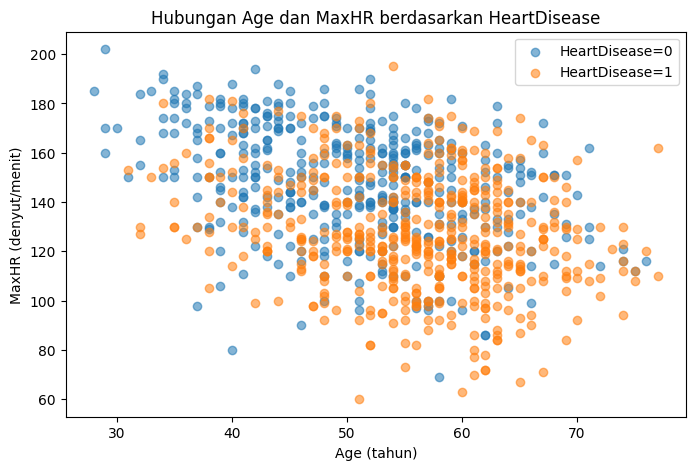

Interpretasi: diagram sebar memperlihatkan pola hubungan dua fitur numerik dan tumpang tindih kelas. Pola ini bersifat eksploratif, bukan hubungan sebab-akibat.


In [ ]:
# Grafik 5 — Hubungan Age dengan MaxHR
plt.figure(figsize=(8, 5))
for label, group in df.groupby(target):
    plt.scatter(group["Age"], group["MaxHR"], alpha=0.55, label=f"HeartDisease={label}")
plt.legend()
plt.title("Hubungan Age dan MaxHR berdasarkan HeartDisease")
plt.xlabel("Age (tahun)")
plt.ylabel("MaxHR (denyut/menit)")
plt.show()
print("Interpretasi: diagram sebar memperlihatkan pola hubungan dua fitur numerik dan tumpang tindih kelas. Pola ini bersifat eksploratif, bukan hubungan sebab-akibat.")

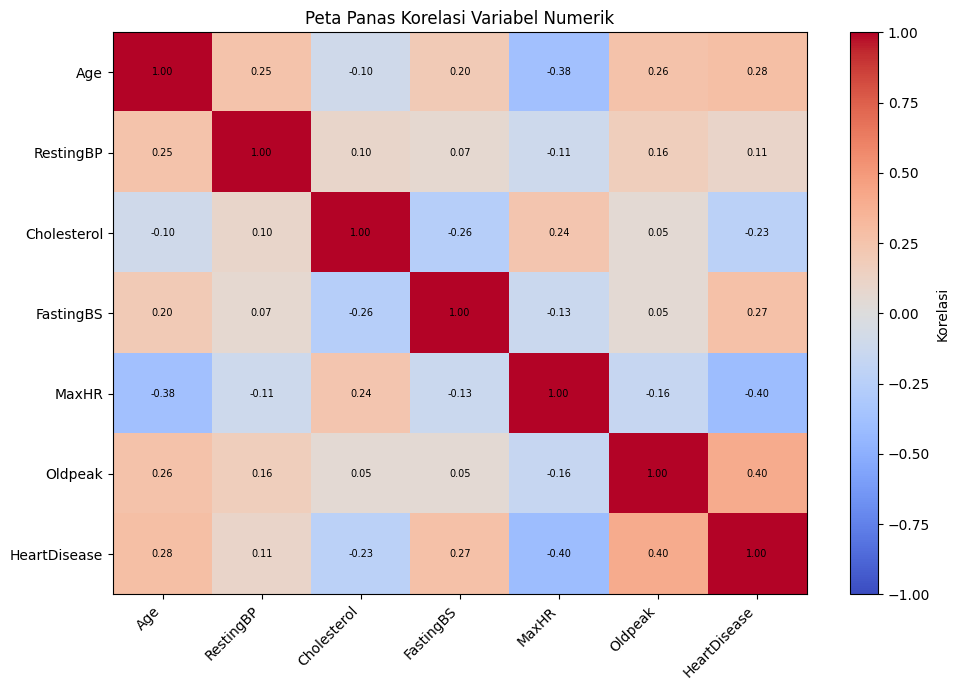

Interpretasi: warna menunjukkan arah dan kekuatan hubungan linear. Korelasi antarf fitur yang kuat perlu dicatat karena dapat memengaruhi asumsi independensi Naive Bayes.


In [ ]:
# Grafik 6 — Korelasi fitur numerik
plt.figure(figsize=(10, 7))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Korelasi")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Peta Panas Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()
print("Interpretasi: warna menunjukkan arah dan kekuatan hubungan linear. Korelasi antarf fitur yang kuat perlu dicatat karena dapat memengaruhi asumsi independensi Naive Bayes.")

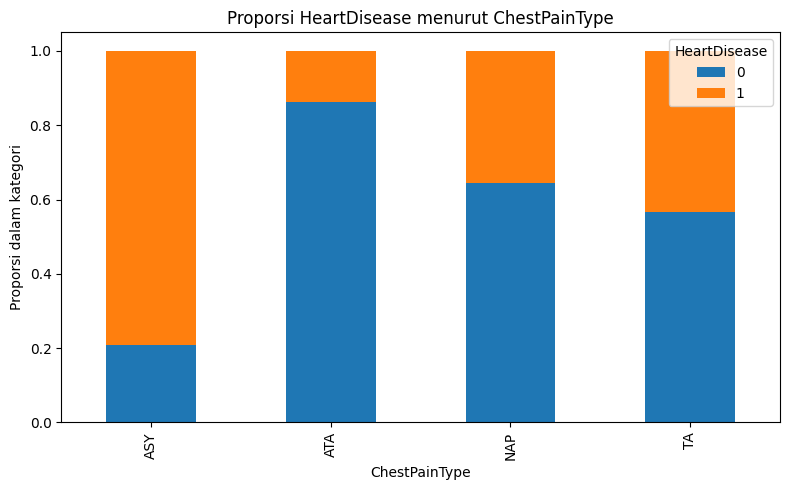

Interpretasi: perbedaan proporsi target antarjenis nyeri dada menunjukkan bahwa distribusi kelas tidak sama pada semua kategori; kategori tetap diperlakukan sebagai nominal.


In [ ]:
# Grafik 7 — Proporsi HeartDisease menurut jenis nyeri dada
ct = pd.crosstab(df["ChestPainType"], df[target], normalize="index")
ct.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Proporsi HeartDisease menurut ChestPainType")
plt.xlabel("ChestPainType")
plt.ylabel("Proporsi dalam kategori")
plt.legend(title="HeartDisease")
plt.tight_layout()
plt.show()
print("Interpretasi: perbedaan proporsi target antarjenis nyeri dada menunjukkan bahwa distribusi kelas tidak sama pada semua kategori; kategori tetap diperlakukan sebagai nominal.")

## 6. Ringkasan temuan EDA dan dugaan awal

1. Dataset memuat 918 pasien dan 12 kolom. Unit analisis adalah pasien.
2. Tidak ada missing eksplisit atau duplikat identik, tetapi terdapat 172 nilai nol pada `Cholesterol` dan 1 pada `RestingBP` yang merupakan missing tersamar menurut panduan paket.
3. Target relatif berimbang; baseline kelas mayoritas dihitung di atas.
4. k-NN memerlukan penskalaan karena rentang fitur numerik berbeda dan fitur kategorikal perlu dikodekan. Penskalaan dan imputasi untuk pemodelan harus dipelajari hanya dari data latih melalui pipeline.
5. Naive Bayes tidak memerlukan penskalaan, tetapi asumsi independensi fitur perlu dibahas jika ditemukan korelasi kuat.

**Dugaan sebelum pemodelan:** fitur `ST_Slope`, `ChestPainType`, `ExerciseAngina`, `Oldpeak`, dan `MaxHR` berpotensi memiliki hubungan dengan target berdasarkan konteks pengukuran dan hasil eksplorasi. Dugaan ini bukan kesimpulan klinis dan akan diuji pada tahap pemodelan.

## 7. Keputusan awal untuk tahap praproses

Keputusan final dan jumlah baris yang terdampak akan dicatat ulang pada notebook `02_praproses.ipynb`. Notebook ini tidak menghapus pencilan secara otomatis.

In [ ]:
keputusan_awal = pd.DataFrame([
    ["RestingBP", "1 nilai nol; tidak mungkin sebagai tekanan darah istirahat", "Ubah 0 menjadi NaN; imputasi median di pipeline setelah split", "Mempertahankan baris dan menghindari imputasi sebelum split", "1 sel"],
    ["Cholesterol", "172 nilai nol; missing tersamar menurut catatan paket", "Ubah 0 menjadi NaN; imputasi median di pipeline setelah split", "Proporsi cukup besar; menghapus baris dapat membuang banyak observasi dan mengubah komposisi kelas", "172 sel"],
    ["Duplikat", "Tidak ditemukan baris identik", "Tidak ada penghapusan", "Tidak ada bukti duplikasi", "0 baris"],
    ["Kolom konstan/identifier", "Tidak ditemukan", "Tidak ada kolom yang dibuang atas dasar ini", "Seluruh 12 kolom punya fungsi yang dapat dijelaskan", "0 kolom"],
    ["Pencilan IQR", "Ada kandidat pencilan statistik pada beberapa fitur", "Pertahankan; jangan hapus otomatis", "Nilai ekstrem belum tentu mustahil secara domain", "Ditinjau per fitur"],
    ["Fitur kategorikal", "Kode kategori terbaca konsisten", "Pertahankan sebagai kategori; one-hot pada pipeline model", "Kode kategori bukan besaran numerik", "Seluruh baris"]
], columns=["Kolom/objek", "Temuan", "Keputusan", "Alasan", "Baris/sel terpengaruh"])
display(keputusan_awal)

print("Ukuran data mentah:", df.shape)
print("Notebook EDA selesai.")

,Kolom/objek,Temuan,Keputusan,Alasan,Baris/sel terpengaruh
0,RestingBP,1 nilai nol; tidak mungkin sebagai tekanan dar...,Ubah 0 menjadi NaN; imputasi median di pipelin...,Mempertahankan baris dan menghindari imputasi ...,1 sel
1,Cholesterol,172 nilai nol; missing tersamar menurut catata...,Ubah 0 menjadi NaN; imputasi median di pipelin...,Proporsi cukup besar; menghapus baris dapat me...,172 sel
2,Duplikat,Tidak ditemukan baris identik,Tidak ada penghapusan,Tidak ada bukti duplikasi,0 baris
3,Kolom konstan/identifier,Tidak ditemukan,Tidak ada kolom yang dibuang atas dasar ini,Seluruh 12 kolom punya fungsi yang dapat dijel...,0 kolom
4,Pencilan IQR,Ada kandidat pencilan statistik pada beberapa ...,Pertahankan; jangan hapus otomatis,Nilai ekstrem belum tentu mustahil secara domain,Ditinjau per fitur
5,Fitur kategorikal,Kode kategori terbaca konsisten,Pertahankan sebagai kategori; one-hot pada pip...,Kode kategori bukan besaran numerik,Seluruh baris


Ukuran data mentah: (918, 12)
Notebook EDA selesai.
